# Лекция 6. Глобализация: линейный поиск и доверительная область

**Курс:** Вычислительная оптимизация · **Часть II. Безусловная оптимизация и ньютоновские методы** · Лекция 6 из 16 · 14 октября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture06.ipynb) · [демо-ноутбук](demo06.ipynb) · [семинар: глобализация в CasADi и IPOPT](seminar06.ipynb) · [разбор упражнений](exercises06.ipynb) · [интерактивная страница «Армихо, Вольфе, доверительная область, CG»](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE)

В конспекте-ноутбуке две демонстрации стоят прямо в тексте: «Демо (a)» — линейный поиск — после раздела 2, «Демо (b)» — доверительная область — после раздела 3. Задачи введения и биография цепи — только в `demo06.ipynb` (части (0) и (d)).

---

> **Код в этом ноутбуке.** Две демонстрации из [`demo06.ipynb`](demo06.ipynb) вставлены в те разделы, к которым относятся: «Демо (a)» — линейный поиск — после раздела 2, «Демо (b)» — доверительная область — после раздела 3; задачи введения и биография цепи — только в `demo06.ipynb`. Вспомогательный код (палитра, методы `armijo`, `wolfe`, `newton_ls`, `bfgs`, `trust_region`, `cg`, `newton_cg`, задачи) вынесен в [`l6helpers.py`](l6helpers.py); его подключает ячейка ниже.

In [1]:
%matplotlib inline

from l6helpers import *  # палитра, методы, задачи (см. файл рядом)

## Пять шагов — и двадцать три миллиарда

Возьмите функцию $f(x)=x\arctan x-\tfrac12\ln(1+x^2)$: гладкую, **строго выпуклую**, с единственным минимумом в нуле. Запустите из $x_0=2$ метод Ньютона:

$$
2\ \to\ -3.54\ \to\ 13.95\ \to\ -279\ \to\ 1.2\cdot10^{5}\ \to\ -2.3\cdot10^{10}.
$$

Пять шагов — и точка улетела на 23 миллиарда. Тот же Ньютон, которому разрешили укорачивать шаг по правилу Армихо, приходит в минимум за **5 итераций**.

**Почему так.** $f'(x)=\arctan x$, $f''(x)=\dfrac{1}{1+x^2}>0$. Шаг Ньютона — вершина параболы-модели $m_k(p)=f(x_k)+f'(x_k)\,p+\tfrac12f''(x_k)\,p^2$:

$$
x_{k+1}=x_k-\frac{f'(x_k)}{f''(x_k)}=x_k-(1+x_k^2)\arctan x_k .
$$

<img src="img/00_atan_newton.png" width="900" alt="слева: f = x arctan x − ½ ln(1+x²) и парабола-модель в x₀ = 2 — её вершина x₁ = −3.54 обещает f = −1.65, а на самом деле там f = 3.28, половина шага даёт 0.27; справа: f' = arctan x с полками ±π/2 — касательная в 2 пересекает ось в −3.54, касательная в −3.54 — в 13.95; порог старта ±1.39">

*Слева: парабола-модель в $x_0=2$ обещает в вершине $x_1=-3.54$ значение $-1.65$, а на самом деле там $f=3.28$ — хуже, чем было ($1.41$); половина шага (синий квадрат) даёт $0.27$. Справа: тот же метод как Ньютон для уравнения $f'(x)=\arctan x=0$ — касательная к почти горизонтальной кривой пересекает ось всё дальше.*

| $k$ | чистый Ньютон, $x_k$ | с Армихо, $x_k$ | $\alpha_k$ |
|---|---|---|---|
| 0 | $2$ | $2$ | — |
| 1 | $-3.54$ | $-0.77$ | $\tfrac12$ |
| 2 | $13.95$ | $0.27$ | $1$ |
| 3 | $-279$ | $-0.013$ | $1$ |
| 4 | $1.2\cdot10^{5}$ | $1.6\cdot10^{-6}$ | $1$ |
| 5 | $-2.3\cdot10^{10}$ | $3\cdot10^{-18}$ | $1$ |

- **Направление всегда верное:** $f''>0$, и шаг $-(1+x^2)\arctan x$ имеет знак, противоположный $x$, — всегда к нулю.
- **Длину парабола врёт:** $f''\to0$ вдали от нуля, парабола с крошечной кривизной очень широка, и её вершина лежит далеко за минимумом; касательная к полке $\pm\pi/2$ пересекает ось далеко.
- **Ошибка возводится в квадрат — и растёт:** при $\lvert x_k\rvert\gg1$ шаг $\approx\tfrac{\pi}{2}x_k^2$, то есть $\lvert x_{k+1}\rvert\approx\tfrac{\pi}{2}x_k^2$ — та же формула, что у квадратичной сходимости $\lvert e_{k+1}\rvert\le C\lvert e_k\rvert^2$, только $C\lvert e_k\rvert>1$. Чистый Ньютон сходится лишь из $\lvert x_0\rvert<1.39$: с порога шаг переносит ровно в $-x_0$.

Армихо отверг полный шаг ($3.28>1.41$) и принял половину ($0.27$); дальше точка внутри порога, и шаги полные. **Модель назначает направление, длину шага проверяет функция** — в этом вся лекция.

### Ещё один пример

<img src="img/00_hooks.png" width="900" alt="две задачи введения: Ньютон на арктангенсе улетает за пять шагов, а с Армихо сходится; Химмельблау — треть стартов чистого Ньютона кончается в седле или максимуме">

- **Химмельблау:** из $36\,\%$ стартов чистый Ньютон приходит не в минимум, а в седло или в максимум. Метод доверительной области из тех же стартов — **в минимум из $100\,\%$**.

### Проблема и два ответа

Ньютон, BFGS и Гаусс–Ньютон — методы *локальные*: быстрые рядом с решением и слепые вдали от него, потому что квадратичная модель честна лишь в окрестности точки. Сегодняшняя тема — **глобализация** (*globalization*): как заставить метод сходиться из любого старта, не потеряв скорость вблизи решения.

**Зачем это вам.** Каждый солвер устроен как «локальный двигатель + глобализация»: SciPy, IPOPT, MATLAB, Ceres, PyTorch. Пока всё работает, глобализации не видно; когда ломается, в логе появляются `alpha_pr = 0.125`, `lg(rg) = 2.0`, «Desired error not necessarily achieved due to precision loss» — и без сегодняшней лекции эти строки ничего не говорят.

**Главный герой лекции — доверие к модели.** Насколько верить $m_k(p)$ и как решать это автоматически — два ответа:

1. **Линейный поиск** (*line search*): направление — из модели, длина шага — по самой функции (раздел 2).
2. **Доверительная область** (*trust region*): сначала радиус, в котором модели верим, потом шаг; радиус настраивается сам (раздел 3).

## 1. Повторение: что мы уже умеем

Лекция начинается с десяти минут повторения: сегодняшние методы — надстройка над всем, что было в лекциях 1–5.

### 1.1. Пять лекций на одной странице

| Лекция | Главная мысль | Число, которое стоит помнить | Где |
|---|---|---|---|
| 1 | Задача = переменные + цель + ограничения; классы LP, QP, выпуклые, NLP; численно решить = найти точку с заданной точностью | цепь: первая сквозная задача | Л1, §3, §6, §7.3 |
| 2 | Выпуклая задача: локальный минимум = глобальный; проверка — гессиан $\succeq0$ | — | Л2, §4, §6 |
| 3 | С ограничениями в решении антиградиент уравновешен нормалями активных ограничений; множители — силы и цены (ККТ) | цепь на полу: множители = силы реакции | Л3, §4–8 |
| 4 | Без ограничений: $\nabla f=0$, $\nabla^2f\succeq0$; спуск сходится линейно, итераций $\sim\kappa$ | Розенброк: $13\,756$ итераций, $\kappa=2508$; цепь $N=40$: $10\,575$ | Л4, §2–5 |
| 5 | Один рецепт «линеаризуй и реши» — Ньютон, BFGS, Гаусс–Ньютон; квадратичная и сверхлинейная сходимость вблизи решения; вдали от решения — правило Армихо для длины шага и сдвиг гессиана при индефинитном гессиане | Розенброк: Ньютон $7$, с Армихо $22$, BFGS $34$; цепь: Ньютон $1$, BFGS с точным шагом $20$ | Л5, §2–6 |

### 1.2. Одна формула и что в ней уже заполнено

Все методы части II — это

$$
\boxed{\;x_{k+1}=x_k+\alpha_kp_k,\qquad p_k=-B_k^{-1}\nabla f(x_k)\;}
$$

**Направление** $p_k$ задаёт матрица кривизны $B_k$: что метод знает о функции. **Длину** задаёт $\alpha_k$. Лекция 4 научилась выбирать $\alpha_k$ для спуска ($B_k=I$), лекция 5 — выбирать $B_k$: гессиан, BFGS, $J^\top J$, $J^\top J+\lambda I$.

<img src="img/01_review.png" width="900" alt="повторение: слева пути спуска, чистого Ньютона, Ньютона с Армихо и BFGS на Розенброке из (−1.2, 1) с числом итераций; справа те же четыре метода на Химмельблау из (0, 0): чистый Ньютон за 5 итераций приходит в максимум, Ньютон с Армихо за 6 — в минимум (3.58, −1.85), спуск за 25 и BFGS за 10 — в минимум (3, 2)">

*Слева: Розенброк из $(-1.2,1)$ — четыре метода лекций 4–5, число итераций в легенде. Справа: Химмельблау из $(0,0)$ — из одного старта чистый Ньютон приходит в максимум, Ньютон с Армихо — в минимум $(3.58,-1.85)$, спуск и BFGS — в минимум $(3,2)$. Куда придёт метод, решает не только модель, но и то, как мы ей доверяем, — об этом сегодня.*

| Метод | $B_k$ | $\alpha_k$ | Скорость вблизи решения | Розенброк из $(-1.2,1)$ |
|---|---|---|---|---|
| градиентный спуск (Л4) | $I$ | backtracking | линейная, множитель $\approx1-1/\kappa$ | $13\,756$ |
| Ньютон (Л5) | $\nabla^2f(x_k)$ | $1$ | квадратичная | $7$ (с выбросом до $(0.76,-3.18)$) |
| Ньютон + Армихо (Л5) | $\nabla^2f$ или $\nabla^2f+\tau I$ | Армихо | квадратичная | $22$ |
| BFGS (Л5) | из секущего уравнения | Армихо | сверхлинейная | $34$ |
| Левенберг–Марквардт (Л5) | $J^\top J+\lambda_kI$ | $1$, а $\lambda_k$ — по $\rho$ | почти квадратичная | синус: $7$ вычислений $r$ |

Сдвиг $\tau I$ — замена $\nabla^2f$ на $\nabla^2f+\tau I$ с $\tau>\lvert\lambda_{\min}(\nabla^2f)\rvert$: к каждому собственному числу прибавляется $\tau$, матрица становится положительно определённой, модель — чашей, и шаг Ньютона снова ведёт вниз; рядом с минимумом $\tau=0$.

Две колонки остались открытыми: **почему** правило Армихо гарантирует сходимость (и гарантирует ли) и **что делать**, когда $B_k$ нельзя ни построить, ни обратить. Это и есть сегодняшняя лекция.

### 1.3. Блиц: шесть вопросов

Ответ — одной фразой; если не получается, ссылка ведёт туда, где он есть.

1. Чем выпуклая задача приятнее невыпуклой?
2. Что в точке минимума с ограничениями уравновешивает антиградиент?
3. Почему спуск на Розенброке делает $13\,756$ итераций?
4. Когда шаг Ньютона ведёт *вверх* по функции?
5. Что измеряет секущее уравнение $B_{k+1}s_k=y_k$?
6. Что Гаусс–Ньютон отбрасывает от гессиана и зачем Левенберг–Марквардт добавляет $\lambda I$?

<details>
<summary>Ответы</summary>

1. Любой локальный минимум глобален, а условие $\nabla f=0$ — не только необходимое, но и достаточное (Л2, §6–7).
2. Нормали активных ограничений с неотрицательными множителями — «силы реакции» (Л3, §4–5).
3. Число обусловленности гессиана у решения $\kappa=2508$: зигзаг поперёк узкой долины, итераций $\sim\kappa\ln(1/\varepsilon)$ (Л4, §5).
4. Когда гессиан индефинитен (*indefinite*: есть и положительные, и отрицательные собственные числа — модель не чаша, а седло): модель — седло, и решение $\nabla^2f\,p=-g$ — её седловая точка (Л5, §3.4).
5. Кривизну вдоль сделанного шага — по разности градиентов, без вторых производных (Л5, §4.2).
6. Отбрасывает $\sum_ir_i\nabla^2r_i$ — дорогую половину гессиана; $\lambda I$ укорачивает шаг там, где линейная модель невязок врёт (Л5, §5.2–5.3).

</details>

### 1.4. Что сегодня

Линейный поиск: правило Армихо, условие Вольфе, теорема о глобальной сходимости (раздел 2) → доверительная область: отношение $\rho$, точка Коши, dogleg, Левенберг–Марквардт как частный случай (3) → что из этого видно в SciPy и в логе IPOPT (4). Семинар — за ноутбуком: глобализация в CasADi и IPOPT (раздел 8).

## 2. Линейный поиск: длину шага проверяет функция

**Главная идея.** Модель знает, *куда* идти, но не знает, *на сколько*. Направление $p_k$ берём из модели, а длину шага $\alpha$ проверяем по самой функции: шаг принят, только если $f$ уменьшилась хотя бы на долю обещанного (правило Армихо, §2.1). С таким правилом метод сходится из любого старта (теорема, §2.3).

### 2.1. Правило Армихо и backtracking

Вдоль луча $f$ — функция одной переменной: $\varphi(\alpha)=f(x_k+\alpha p_k)$. По правилу сложной функции $\varphi'(\alpha)=\nabla f(x_k+\alpha p_k)^\top p_k$ — производная по направлению $p_k$; в нуле $\varphi'(0)=g_k^\top p_k<0$ — это обещание модели: на единицу длины шага $f$ должна упасть на $\lvert g_k^\top p_k\rvert$.

**Пример — выброс Ньютона на Розенброке** (картинка повторения). В $x_1=(-1.175,\,1.381)$ шаг Ньютона длиной $4.95$ ведёт в $f=1412$ — в $300$ раз больше $\varphi(0)=4.73$, хотя при $\alpha\approx0.11$ функция падает до $4.06$; обещание $\varphi'(0)=(-4.64)(1.94)+(-0.12)(-4.56)=-8.43$. Направление угадано, длина — нет.

<img src="img/02_alpha_cut.png" width="900" alt="слева: линии уровня Розенброка, старт x₀, точка x₁ и шаг Ньютона p₁ — полный шаг (α = 1) уводит в (0.76, −3.18), где f = 1412, а точка α = 0.11 на том же луче даёт f = 4.06; справа: разрез φ(α) = f(x₁ + α p₁) в логарифмической шкале — провал до 4.06 при α ≈ 0.11 и подъём до 1412 при α = 1">

*Слева: шаг $p_1$ на линиях уровня — направление ведёт вниз по долине, но полная длина выносит далеко за неё. Справа: разрез $\varphi(\alpha)$ вдоль шага — минимум при $\alpha\approx0.11$, при $\alpha=1$ значение в $300$ раз больше исходного.*

**Правило Армихо** (*Armijo*, 1966):

$$
\varphi(\alpha)\le\varphi(0)+c_1\,\alpha\,\varphi'(0),\qquad 0<c_1<1,\quad\text{обычно } c_1=10^{-4} .
$$

Справа — прямая из $\varphi(0)$ с наклоном в $c_1$ раз положе касательной: шаг принят, если $\varphi$ под ней. Без $c_1$, с одним «стало меньше», уменьшения могут быть сколь угодно малыми, и метод остановится где угодно.

<img src="img/02_armijo_c1.png" width="900" alt="φ(α) вдоль шага Ньютона из x₀ = 2 на арктангенсе, касательная в нуле и прямая Армихо при c₁ = 0.25; α = 1 (φ = 3.28) выше прямой — отказ, α = ½ (0.27) под ней — принят">

*$\varphi(\alpha)$ вдоль шага Ньютона из $x_0=2$ на арктангенсе из введения; прямая Армихо нарисована при $c_1=0.25$, чтобы была видна. $\alpha=1$ выше прямой — отказ, $\alpha=\tfrac12$ под ней — принят.*

**Backtracking:** $\alpha=1$; пока Армихо не выполнено, $\alpha\leftarrow\alpha/2$. Цикл конечен, а шаг не мельчает: если кривизна $f$ ограничена (точное условие — §2.3), деление остановится на $\alpha_k\ge\alpha_{\min}>0$ (пункт 2 идеи доказательства, §2.3). На Розенброке из $x_1$: $\alpha=1$ ($f=1412$), $\tfrac12$, $\tfrac14$ — отказ, $\tfrac18$ — принято; тот же шаг $0.125$ на той же итерации делает IPOPT (столбец `alpha_pr` его лога, семинар).

<img src="img/11_backtracking.gif" width="900" alt="анимация: backtracking на графике φ(α) для Розенброка в точке x_1 — кандидаты α = 1, 1/2, 1/4 выше прямой Армихо и отвергнуты, 1/8 принят; справа те же точки на линиях уровня">

*Backtracking на Розенброке: $1,\tfrac12,\tfrac14$ отвергнуты, $\tfrac18$ принят.*

### 2.2. Условие Вольфе: шаг не слишком короткий

Армихо отсекает слишком длинные шаги, но слишком короткие пропускает: при крошечном $\alpha$ функция идёт по касательной, и неравенство Армихо выполнено автоматически. Как понять, что шаг не слишком короткий? По наклону $\varphi'(\alpha)$ в новой точке. В начале луча спуск крутой: $\varphi'(0)<0$. Пока мы идём по склону, наклон почти не меняется; у дна он выполаживается до нуля, а за дном становится положительным. **Условие кривизны Вольфе** (*Wolfe*, 1969) требует, чтобы наклон стал заметно положе исходного:

$$
\varphi'(\alpha)\ge c_2\,\varphi'(0),\qquad c_1<c_2<1 .
$$

При $c_2=0.9$ достаточно, чтобы спуск стал на $10\,\%$ положе. **Сильное** условие Вольфе $\lvert\varphi'(\alpha)\rvert\le c_2\lvert\varphi'(0)\rvert$ запрещает ещё и крутой подъём — перелёт далеко за минимум $\varphi$.

**Вопрос залу.** На $\varphi(\alpha)$ Розенброка в $x_1$ три кандидата: $\alpha=0.02$, $0.125$, $0.25$. Какие проходят Армихо? Какие — Вольфе?

<img src="img/02_armijo_wolfe.png" width="900" alt="φ(α) для Розенброка в x_1 вдоль шага Ньютона: прямая Армихо, допустимые по Армихо шаги α ≤ 0.176, по Вольфе 0.044 ≤ α ≤ 0.176; кандидаты 0.02 — только Армихо, 0.125 — оба условия, 0.25 — ни одного">

*Ответ: $0.02$ — только Армихо (склон ещё крутой, шаг короткий), $0.125$ — оба условия, $0.25$ — ни одного (перелёт).* Покрутить руками — сцена «Армихо и Вольфе» на [интерактивной странице](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE).

**Кому это нужно.** Backtracking от $\alpha=1$ коротких шагов и так не делает. Но BFGS строит матрицу по разности градиентов и требует, чтобы вдоль шага кривизна была положительной, $s_k^\top y_k>0$; именно это гарантирует условие кривизны. Так устроен линейный поиск в SciPy: $c_1=10^{-4}$, $c_2=0.9$. Коротко: Армихо — «убыль достаточно», Вольфе — «убыль достаточно и не топчись на месте».

### 2.3. Теорема о глобальной сходимости

**Что обещает теорема.** Если функция ограничена снизу, её кривизна ограничена, направления — честный спуск, а длину шага выбирает backtracking по Армихо, то градиент стремится к нулю — откуда бы мы ни стартовали.

**Почему.** Каждый принятый шаг уменьшает $f$ не меньше чем на $C\lVert g_k\rVert^2$ — на величину, пропорциональную квадрату градиента. Всего уменьшить $f$ можно не больше чем на $f_0-\inf f$, потому что функция ограничена снизу. Значит, сумма квадратов градиентов конечна, и градиент обязан стремиться к нулю.

**Чего не обещает.** Ни скорости, ни того, что предельная точка — минимум, а не седло (упражнение 6.2).

**Формулировка.** Пусть $f:\mathbb R^n\to\mathbb R$ дифференцируема, $g_k=\nabla f(x_k)$, $f_k=f(x_k)$, и:

1. $f$ **ограничена снизу** — есть куда спускаться, но не бесконечно;
2. **градиент липшицев** (*Lipschitz continuous*) с константой $L>0$: $\lVert\nabla f(x)-\nabla f(y)\rVert\le L\lVert x-y\rVert$ для всех $x,y$. Словами: кривизна $f$ ограничена числом $L$ — для дважды дифференцируемой $f$ это $f''\le L$ в одной переменной и $\nabla^2f\preceq LI$ в $n$; у арктангенса из введения $f''=1/(1+x^2)\le1$, так что $L=1$;
3. **направления — честный спуск:** $p_k=-B_k^{-1}g_k$, где $B_k=B_k^\top$ и все собственные числа $B_k$ лежат в $[m_B,M_B]$, $m_B>0$. То есть угол между $p_k$ и $-g_k$ не подходит к $90^\circ$, а длина $p_k$ соразмерна $\lVert g_k\rVert$. Для спуска $B_k=I$; для Ньютона это требование держать гессиан положительно определённым — сдвиг $\tau I$ не косметика, а условие теоремы;
4. **длина шага — backtracking по Армихо** от $\alpha=1$ с делением пополам (§2.1).

**Теорема** (Зойтендейк; Nocedal & Wright, теорема 3.2). Тогда $\lVert\nabla f(x_k)\rVert\to0$ при $k\to\infty$ из любого начального приближения.

**Идея доказательства — четыре строки.**

1. *Направление честное.* Собственные числа $B_k^{-1}$ лежат в $[1/M_B,\,1/m_B]$, поэтому $-g_k^\top p_k\ge\lVert g_k\rVert^2/M_B$ и $\lVert p_k\rVert\le\lVert g_k\rVert/m_B$.
2. *Шаг не мельчает.* Из ограниченной кривизны $f(x_k+\alpha p_k)\le f_k+\alpha g_k^\top p_k+\tfrac L2\alpha^2\lVert p_k\rVert^2$, поэтому Армихо заведомо выполнено при всех $\alpha\le\bar\alpha_k=\dfrac{2(1-c_1)(-g_k^\top p_k)}{L\lVert p_k\rVert^2}$, и backtracking останавливается на $\alpha_k\ge\min(1,\bar\alpha_k/2)$.
3. *Каждый шаг съедает кусок $\lVert g_k\rVert^2$.* Подставляем 1 и 2 в правило Армихо: $f_k-f_{k+1}\ge c_1\alpha_k(-g_k^\top p_k)\ge C\lVert g_k\rVert^2$, где $C>0$ зависит только от $c_1$, $L$, $m_B$, $M_B$.
4. *Суммируем.* $C\sum_k\lVert g_k\rVert^2\le f_0-\inf f<\infty$; члены сходящегося ряда стремятся к нулю: $\lVert g_k\rVert\to0$.

Полное доказательство с выводом каждого неравенства — разбор упражнения 6.1.

**Пример.** Арктангенс из введения: $L=1$; Армихо не выпускает итерации из отрезка $[-2,2]$ (там $f\le f(2)$), где $f''\ge\tfrac15$, то есть $m_B=\tfrac15$, $M_B=1$. Условия выполнены — Ньютон с Армихо сходится из любого старта; чистый Ньютон ($\alpha_k\equiv1$, условие 4 нарушено) — только из $\lvert x_0\rvert<1.39$.

### Демо (a). Линейный поиск: Армихо, Вольфе, backtracking

**Что проверяем.** Числа §2.1–2.2: на Розенброке в $x_1$ (первая итерация Ньютона из $(-1.2,1)$) шаг Ньютона длиной $4.95$ ведёт в $f=1412$; Армихо выполнено при $\alpha\le0.176$, Вольфе ($c_2=0.9$) — при $0.044\le\alpha\le0.176$; backtracking пробует $1,\tfrac12,\tfrac14$ и принимает $\tfrac18$.

In [2]:
x1 = X0_ROSEN - np.linalg.solve(rosen_hess(X0_ROSEN), rosen_grad(X0_ROSEN))   # x1: первая итерация Ньютона из (-1.2, 1)
p1 = -np.linalg.solve(rosen_hess(x1), rosen_grad(x1))                           # p1: шаг Ньютона в x1 (длина 4.95)
phi = lambda a: rosen(x1 + a * p1)              # разрез f вдоль шага: phi(alpha) = f(x1 + alpha * p1)
dphi = lambda a: rosen_grad(x1 + a * p1) @ p1   # производная разреза по правилу сложной функции: grad f(x1 + alpha p1) . p1
print(f"x1 = {x1.round(4)}, |p1| = {np.linalg.norm(p1):.3f}, φ(0) = {phi(0):.3f}, φ(1) = {phi(1):.1f}, φ'(0) = {dphi(0):.3f}   (в конспекте: 4.95, 4.73, 1412, -8.43)")

al = np.linspace(0, 0.3, 30001)                                        # сетка длин шага alpha
arm = np.array([phi(a) <= phi(0) + 1e-4 * a * dphi(0) for a in al])   # правило Армихо: phi под прямой с наклоном c1 phi'(0), c1 = 1e-4
wol = arm & np.array([dphi(a) >= 0.9 * dphi(0) for a in al])          # плюс условие кривизны Вольфе: наклон стал положе, c2 = 0.9
print(f"Армихо: α ≤ {al[arm].max():.3f};  Вольфе: {al[wol].min():.3f} ≤ α ≤ {al[wol].max():.3f}   (в конспекте: 0.176; 0.044–0.176)")

for a in [1, 0.5, 0.25, 0.125]:                                        # backtracking: alpha = 1, затем пополам, пока Армихо не выполнено
    ok = phi(a) <= phi(0) + 1e-4 * a * dphi(0)
    print(f"  α = {a:<6g} φ = {phi(a):9.3f}  Армихо: {'да — принят' if ok else 'нет'}")

x1 = [-1.1753  1.3807], |p1| = 4.951, φ(0) = 4.732, φ(1) = 1411.8, φ'(0) = -8.433   (в конспекте: 4.95, 4.73, 1412, -8.43)


Армихо: α ≤ 0.176;  Вольфе: 0.044 ≤ α ≤ 0.176   (в конспекте: 0.176; 0.044–0.176)
  α = 1      φ =  1411.845  Армихо: нет
  α = 0.5    φ =    89.749  Армихо: нет
  α = 0.25   φ =     8.395  Армихо: нет
  α = 0.125  φ =     4.087  Армихо: да — принят


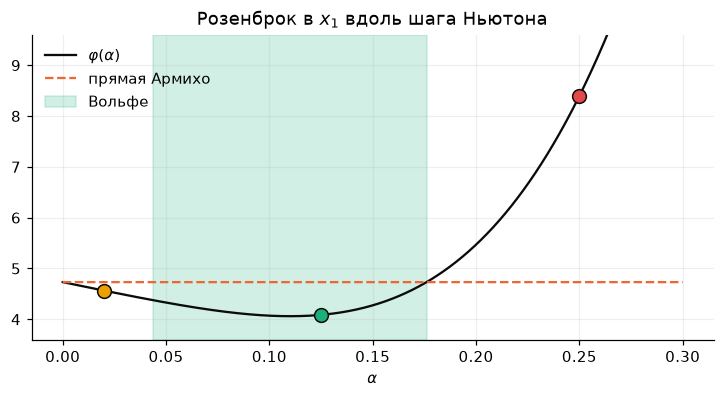

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(al, [phi(a) for a in al], color=INK, label=r"$\varphi(\alpha)$")                 # разрез phi(alpha)
ax.plot(al, phi(0) + 1e-4 * al * dphi(0), "--", color=ORANGE, label="прямая Армихо")       # прямая Армихо: phi(0) + c1 alpha phi'(0)
ax.axvspan(al[wol].min(), al[wol].max(), color=AQUA, alpha=0.2, label="Вольфе")            # допустимые по Вольфе шаги
for a, col in [(0.02, YELLOW), (0.125, AQUA), (0.25, RED)]:                                 # три кандидата из «вопроса залу»
    ax.plot(a, phi(a), "o", color=col, ms=9, mec=INK)                                        #   0.02 — только Армихо, 0.125 — оба, 0.25 — ни одного
ax.set(ylim=(3.6, 9.6), xlabel=r"$\alpha$", title="Розенброк в $x_1$ вдоль шага Ньютона")
ax.legend(); plt.show()

## 3. Доверительная область: сначала радиус, потом шаг

**Тезис простыми словами.** Линейный поиск выбирает направление, а потом длину. Доверительная область (*trust region*) делает наоборот: сначала решает, **в каком радиусе $\Delta$ модели можно верить**, и ищет лучшую точку модели внутри этого шара. Радиус настраивается сам — по тому, насколько модель угадала.

### 3.1. Подзадача: лучшая точка модели в шаре радиуса $\Delta$

Модель — та же квадратичная, что у Ньютона: $m_k(p)=f_k+g_k^\top p+\tfrac12p^\top B_kp$, где $B_k$ — гессиан или его замена, а $p\in\mathbb R^n$ — **вектор шага**, кандидат в следующую точку $x_k+p$. Без ограничений минимум модели — шаг Ньютона $p=-B_k^{-1}g_k$, которому далеко от $x_k$ верить нельзя. Доверительная область верит модели только в шаре радиуса $\Delta_k$ вокруг $x_k$ и берёт лучшую точку модели в этом шаре:

$$
\min_{p\in\mathbb R^n}\ \underbrace{f_k+g_k^\top p+\tfrac12p^\top B_kp}_{\text{модель }m_k(p)}
\qquad\text{при}\qquad
\underbrace{\lVert p\rVert\le\Delta_k}_{\text{шаг не длиннее }\Delta_k} .
$$

Если точка Ньютона лежит внутри шара, она и есть решение — шаг чисто ньютоновский. Если снаружи (или $B_k$ индефинитна — собственные числа разных знаков — и минимума у модели нет вовсе), решение лежит **на сфере** $\lVert p\rVert=\Delta_k$, и это не обрезанный шаг Ньютона: у него другая длина *и* другое направление. На Розенброке в $x_1$ шаг Ньютона имеет длину $4.95$ (§2.1); при $\Delta_1=1$ подзадача выдаёт шаг длиной ровно $1$.

**Пример — функция из введения, дополненная второй координатой:** $f(x)=x_1\arctan x_1-\tfrac12\ln(1+x_1^2)+\tfrac12x_2^2$, старт $(2,1)$. Её модель в старте — параболоид с вершиной в $(-3.54,\,0)$.

<img src="img/05_tr_model.png" width="900" alt="слева: линии уровня функции x₁ arctan x₁ − ½ ln(1+x₁²) + ½ x₂² (серые) и параболы-модели в точке (2, 1) — синие пунктирные эллипсы с центром в вершине (−3.54, 0), где модель обещает −1.65, а f = 3.28; стрелка Ньютона в вершину, круг Δ = 1 и шаг доверительной области на его границе (модель 0.65, на деле 0.67); справа: два пути из (2, 1) — Ньютон уходит в −3.54, затем в 13.95 и дальше, доверительная область за 6 итераций приходит в минимум (0, 0)">

*Слева: рядом со стартом парабола-модель (синие эллипсы) и функция (серые линии) совпадают, вдали расходятся — в вершине модель обещает $-1.65$, а на самом деле $f=3.28$. Ньютон прыгает в вершину (красная стрелка). Доверительная область берёт лучшую точку параболы в круге $\Delta=1$ (зелёный квадрат): модель обещала $0.65$, получилось $0.67$ — шаг принят, круг удвоен. Справа: два пути из одного старта. Ньютон улетает — $-3.54$, $13.95$, $-279$, как в введении; доверительная область за $6$ итераций приходит в минимум $(0,0)$, причём уже второй шаг — полный ньютоновский: вершина попала внутрь круга.*

**Ньютон — та же модель без круга** ($\Delta=\infty$): он всегда прыгает в вершину параболы. Доверительная область делает это, только когда вершина лежит внутри круга; иначе идёт до границы — и по другому направлению.

### 3.2. Отношение $\rho_k$ и алгоритм целиком

Решили подзадачу — получили кандидата $p_k$. Модель **обещала** уменьшение $m_k(0)-m_k(p_k)$ (всегда $\ge0$: $p=0$ тоже лежит в шаре); **фактически** $f$ изменилась на $f(x_k)-f(x_k+p_k)$. Их отношение

$$
\rho_k=\frac{f(x_k)-f(x_k+p_k)}{m_k(0)-m_k(p_k)}=\frac{\text{фактическое уменьшение}}{\text{обещанное моделью}} .
$$

$\rho_k\approx1$ — модель сказала правду; $\rho_k$ много меньше $1$ — преувеличила; $\rho_k<0$ — функция выросла. Отсюда правила для шага и радиуса:

| $\rho_k$ | Модель | Шаг | Радиус |
|---|---|---|---|
| $\rho_k<\tfrac14$ | врёт | принять, только если $\rho_k>\eta$ | $\Delta/4$ |
| $\tfrac14\le\rho_k\le\tfrac34$ | терпима | принять | не менять |
| $\rho_k>\tfrac34$, шаг на границе | хороша и упёрлась в лимит | принять | $\min(2\Delta,\Delta_{\max})$ |

У нас $\eta=0.1$, $\Delta_0=1$, $\Delta_{\max}=10$ (Nocedal & Wright, алгоритм 4.1); после отвергнутого шага остаёмся в $x_k$ и решаем подзадачу заново с меньшим радиусом.

**Алгоритм** (Nocedal & Wright, алгоритм 4.1). Дано $x_0$, $\Delta_0=1$, $\Delta_{\max}=10$, $\eta=0.1$. Для $k=0,1,2,\dots$:

1. вычислить $f_k$, $g_k=\nabla f(x_k)\in\mathbb R^n$ и $B_k=\nabla^2f(x_k)\in\mathbb R^{n\times n}$; если $\lVert g_k\rVert\le\varepsilon$ — стоп;
2. решить подзадачу: $p_k$ — лучшая точка модели в шаре $\lVert p\rVert\le\Delta_k$ (как её искать — §3.3);
3. вычислить $f(x_k+p_k)$ — одно значение функции — и $\rho_k$;
4. радиус: при $\rho_k<\tfrac14$ — $\Delta_{k+1}=\Delta_k/4$; при $\rho_k>\tfrac34$ и $\lVert p_k\rVert=\Delta_k$ — $\Delta_{k+1}=\min(2\Delta_k,\Delta_{\max})$; иначе $\Delta_{k+1}=\Delta_k$;
5. шаг: при $\rho_k>\eta$ — $x_{k+1}=x_k+p_k$, иначе $x_{k+1}=x_k$, и подзадача решается заново с меньшим радиусом.

Ньютон — это шаги 1–2 при $\Delta_k=\infty$ без проверок 3–5.

**Трасса на Розенброке** (отвергнутые шаги — красные кресты на картинке §3.4). Итерация 1: $x_1=(-1.175,\,1.381)$, $f_1=4.73$, $\Delta_1=1$; шаг 2 — точка на сфере; шаг 3 — модель обещала уменьшить $f$ на $1.54$, а $f(x_1+p_1)=5.39$, рост на $0.66$: $\rho_1=-0.66/1.54=-0.43$; шаг 4 — $\Delta_2=0.25$; шаг 5 — остаёмся в $x_1$. Итерация 2: та же точка, $\Delta_2=0.25$: обещано $0.42$, получено $0.43$, $\rho_2=1.01$ — шаг принят, и, раз он упёрся в границу, $\Delta_3=0.5$.

### 3.3. Как решить подзадачу: точка Коши, dogleg, точный шаг

| Способ | Как строится | Что нужно | Розенброк из $(-1.2,1)$ |
|---|---|---|---|
| **точка Коши** (*Cauchy point*) | минимум модели вдоль $-g$, обрезанный шаром | только $g$ | $14\,110$ итераций — это спуск с точным шагом |
| **dogleg** (Powell, 1970) | ломаная: из нуля в минимум вдоль $-g$, оттуда в точку Ньютона; шаг — где ломаная выходит из шара | $B\succ0$ | $24$ |
| **точный шаг** | $(B+\lambda I)p=-g$: $\lambda=0$, если точка Ньютона внутри шара, иначе $\lambda>0$ такое, что $\lVert p\rVert=\Delta$ | разложение $B$ | $25$ |

<img src="img/05_tr_subproblem.png" width="900" alt="слева: одна подзадача — эллипсы модели g = (3, 4), B = diag(1, 5), круг Δ = 2 — и три ответа: точка Коши на луче −g внутри круга (m = −3.51), ломаная dogleg через точку Коши к точке Ньютона и её шаг на выходе из круга (m = −5.21), кривая p(λ) от точки Ньютона к направлению −g и точный шаг на пересечении с кругом (m = −5.44); справа: длина шага |(B + λI)⁻¹g| по λ, горизонталь Δ = 2 пересекает кривую при λ = 0.61, горизонталь Δ = 3.5 выше точки Ньютона — λ = 0">

*Слева: одна подзадача — модель-чаша $g=(3,4)$, $B=\operatorname{diag}(1,5)$, круг $\Delta=2$ — и три ответа. Точка Коши — минимум модели вдоль $-g$ (здесь он внутри круга), $m=-3.51$. Dogleg — ломаная от $x_k$ через точку Коши к точке Ньютона; шаг там, где она выходит из круга, $m=-5.21$. Точный шаг — кривая $p(\lambda)=-(B+\lambda I)^{-1}g$ от точки Ньютона ($\lambda=0$) к направлению $-g$ (большие $\lambda$); шаг там, где она пересекает круг, $m=-5.44$. Справа — как найти точный шаг: длина $\lVert p(\lambda)\rVert$ убывает по $\lambda$, и остаётся решить одно уравнение $\lVert p(\lambda)\rVert=\Delta$ — здесь $\lambda=0.61$. Если круг больше точки Ньютона ($\Delta=3.5$), уравнение решать не нужно: $\lambda=0$, шаг ньютоновский.*

Если $B$ индефинитна (собственные числа разных знаков), у модели нет минимума на всей плоскости, но в круге он есть всегда: точный шаг уходит на границу вдоль отрицательной кривизны, прочь от седла. Отсюда $100\,\%$ минимумов на Химмельблау без всякого сдвига $\tau I$.

Для глобальной сходимости достаточно, чтобы шаг уменьшал модель не хуже точки Коши (Nocedal & Wright, теоремы 4.5–4.6); dogleg и точный шаг к тому же дают скорость Ньютона. Формула точки Коши — упражнение 6.3.

**Связь с Левенбергом–Марквардтом.** Уравнение точного шага $(B+\lambda I)p=-g$ — это Левенберг–Марквардт при $B=J^\top J$ и сдвиг $\tau I$ демпфированного Ньютона: три лекарства — один объект, а маленький $\Delta$ ↔ большой $\lambda$ ↔ короткий шаг почти против градиента. Точная формулировка (Moré–Sorensen, 1983): $p^\ast$ решает подзадачу тогда и только тогда, когда при некотором $\lambda\ge0$ выполнено $(B+\lambda I)p^\ast=-g$, $\lambda(\Delta-\lVert p^\ast\rVert)=0$ и $B+\lambda I\succeq0$ (упражнение 6.5).

### 3.4. Доверительная область на Розенброке

<img src="img/06_tr_rosenbrock.png" width="900" alt="доверительная область с точным шагом на Розенброке из (-1.2, 1): путь и круги радиуса Δ_k; справа радиус Δ_k и отношение ρ_k по итерациям, три отвергнутых шага отмечены">

<img src="img/12_tr_breathes.gif" width="900" alt="анимация: доверительная область дышит — круг радиуса Δ_k вокруг текущей точки на Розенброке, точка модели и ρ_k в заголовке; радиус сжимается после неудачных шагов и растёт у решения">

*Анимация: круг доверия $\Delta_k$ вокруг текущей точки. После шагов с плохим $\rho$ он сжимается, на прямом участке долины — растёт. В заголовке кадра — номер итерации, $\Delta_k$ и $\rho_k$.*

Из $(-1.2,1)$:
- первый шаг Ньютона лежит внутри шара и принимается;
- во второй итерации шаг Ньютона длиной $4.95$ (тот самый выброс) обрезан до границы $\Delta=1$ — и всё равно $\rho=-0.43$: функция выросла, шаг отвергнут, $\Delta$ уменьшен вчетверо;
- дальше метод идёт по долине, радиус дышит;
- у решения шаги снова чисто ньютоновские.

Итого: $25$ итераций, из них $3$ пробных шага отвергнуты, ни одного подъёма по $f$. Покрутить руками — сцена «Доверительная область» на [интерактивной странице](https://claude.ai/artifact/KniuVJGw3XPZvWVeDtBpwE): клик задаёт старт, переключатель «точный / dogleg / точка Коши», снизу — подзадача в текущей точке.

**Линейный поиск или доверительная область?**

| | Линейный поиск | Доверительная область |
|---|---|---|
| сначала выбирается | направление | радиус |
| отрицательная кривизна | нужен сдвиг $\tau I$ | обрабатывается сама |
| неудачный шаг | укорачиваем вдоль того же луча | решаем подзадачу заново: шаг меняет и длину, и направление |
| цена итерации | одна система + несколько $f$ | подзадача (дороже), обычно одно $f$ |
| где | SciPy `BFGS`, `L-BFGS-B`; IPOPT; PyTorch `LBFGS` | SciPy `trust-*`, `least_squares`; MATLAB `fsolve`; Ceres |

**Реальный кейс.** Внутри Google Ceres Solver (восстановление 3D-сцен из миллионов фотографий), `scipy.optimize.least_squares` (метод `trf` по умолчанию) и MATLAB `fsolve` (`trust-region-dogleg` по умолчанию) — доверительная область.

### Демо (b). Доверительная область: $\rho$, точка Коши, dogleg

**Что проверяем.** Модельная задача §3.3: $g=(3,4)$, $B=\operatorname{diag}(1,5)$ — точка Ньютона $(-3,-0.8)$, модель в ней $-6.1$; при $\Delta=2$ точка Коши $(-0.84,-1.12)$ с моделью $-3.51$, dogleg $-5.21$, точный шаг $-5.44$. Затем метод целиком на Розенброке: $25$ итераций, из них $3$ пробных шага отвергнуты. В каждой ячейке — числа и картинка.

точка Ньютона [-3.  -0.8], |pN| = 3.105, m = -6.100;  минимум вдоль -g: [-0.843 -1.124], |pU| = 1.404
Δ = 1.0: Коши [-0.6 -0.8] m =  -3.220 | dogleg [-0.6 -0.8] m =  -3.220 | точный [-0.848 -0.531] m =  -3.602
Δ = 2.0: Коши [-0.843 -1.124] m =  -3.511 | dogleg [-1.738 -0.989] m =  -5.214 | точный [-1.868 -0.714] m =  -5.441
Δ = 3.0: Коши [-0.843 -1.124] m =  -3.511 | dogleg [-2.887 -0.817] m =  -6.093 | точный [-2.893 -0.794] m =  -6.094
Δ = 4.0: Коши [-0.843 -1.124] m =  -3.511 | dogleg [-3.  -0.8] m =  -6.100 | точный [-3.  -0.8] m =  -6.100


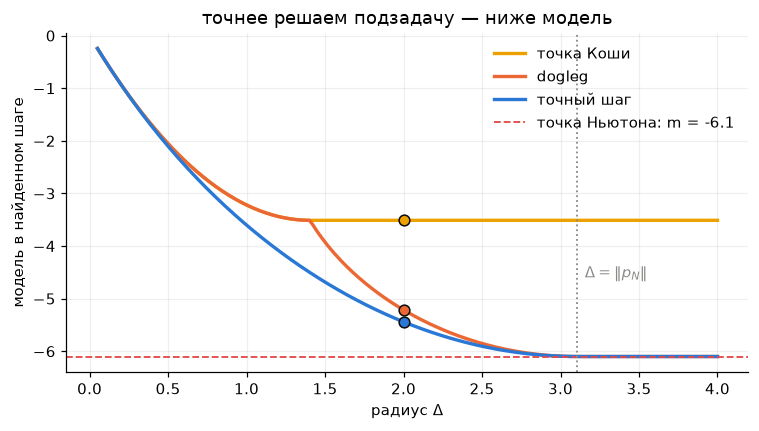

In [4]:
g_t, B_t = np.array([3.0, 4.0]), np.diag([1.0, 5.0])   # модель-чаша из §3.3
m = lambda p: g_t @ p + 0.5 * p @ B_t @ p                 # модель m(p) (без постоянной f_k)
pN = -np.linalg.solve(B_t, g_t); pU = -(g_t @ g_t) / (g_t @ B_t @ g_t) * g_t
print(f"точка Ньютона {pN}, |pN| = {np.linalg.norm(pN):.3f}, m = {m(pN):.3f};  минимум вдоль -g: {pU.round(3)}, |pU| = {np.linalg.norm(pU):.3f}")
for D in [1.0, 2.0, 3.0, 4.0]:
    pc, pd, pe = cauchy_point(g_t, B_t, D), dogleg(g_t, B_t, D), tr_exact(g_t, B_t, D)
    print(f"Δ = {D}: Коши {pc.round(3)} m = {m(pc):7.3f} | dogleg {pd.round(3)} m = {m(pd):7.3f} | точный {pe.round(3)} m = {m(pe):7.3f}")

Ds = np.linspace(0.05, 4.0, 200)                           # радиусы
fig, ax = plt.subplots(figsize=(8, 4))
for name, solver, col in [("точка Коши", cauchy_point, YELLOW), ("dogleg", dogleg, ORANGE), ("точный шаг", tr_exact, BLUE)]:
    ax.plot(Ds, [m(solver(g_t, B_t, D)) for D in Ds], color=col, lw=2.2, label=name)   # модель в найденном шаге
    ax.plot(2.0, m(solver(g_t, B_t, 2.0)), "o", color=col, mec=INK, ms=7, zorder=5)     # Δ = 2 — числа конспекта
ax.axhline(m(pN), color=RED, ls="--", lw=1.2, label=f"точка Ньютона: m = {m(pN):.1f}")  # ниже не опустится никто
ax.axvline(np.linalg.norm(pN), color=GRAY, ls=":", lw=1.2)                               # |pN| = 3.10: дальше все три совпадают
ax.text(np.linalg.norm(pN) + 0.05, -4.6, "$\\Delta=\\|p_N\\|$", color=GRAY)
ax.set(xlabel="радиус $\\Delta$", ylabel="модель в найденном шаге", title="точнее решаем подзадачу — ниже модель")
ax.legend(loc="upper right")
plt.show()

Точный шаг всегда не хуже dogleg, dogleg — не хуже точки Коши; при $\Delta\ge\lVert p_N\rVert=3.10$ все три — точка Ньютона. Точка Коши перестаёт расти уже при $\Delta=1.40$: дальше вдоль $-g$ модель не убывает. **Предскажите до запуска:** сколько итераций сделает доверительная область на Розенброке, если брать *только* точку Коши? (Подсказка: это спуск с точным шагом, обрезанным шаром.)

exact  :     25 итераций, отвергнуто 3, x = [1. 1.], 0.0 с
dogleg :     24 итераций, отвергнуто 3, x = [1. 1.], 0.0 с


cauchy :  14110 итераций, отвергнуто 2, x = [0.999999 0.999998], 0.2 с
в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756


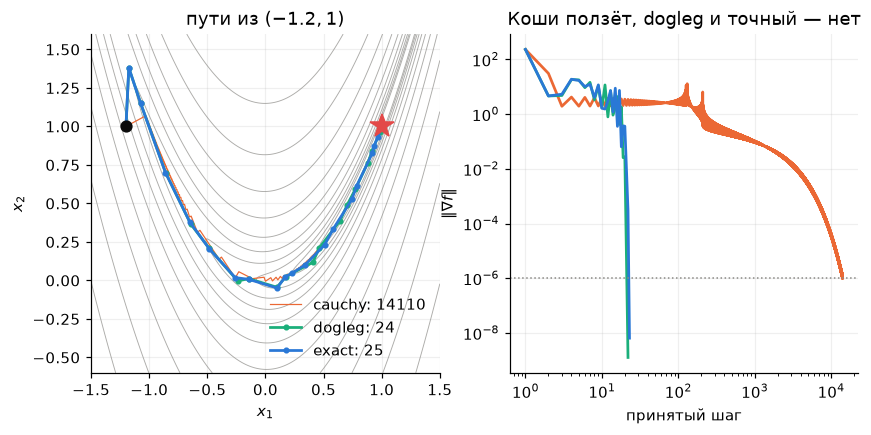

In [5]:
runs = {}
for step in ["exact", "dogleg", "cauchy"]:
    t0 = time.perf_counter()
    x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step=step)
    runs[step] = (k, path)                                  # число итераций и принятые точки
    rej = sum(not h[4] for h in hist)
    print(f"{step:7s}: {k:6d} итераций, отвергнуто {rej}, x = {x.round(6)}, {time.perf_counter() - t0:.1f} с")
print("в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756")

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
rosen_contour(axs[0], xlim=(-1.5, 1.5), ylim=(-0.6, 1.6))                         # линии уровня Розенброка
for step, col in [("cauchy", ORANGE), ("dogleg", AQUA), ("exact", BLUE)]:
    k, path = runs[step]
    style = dict(lw=0.8) if step == "cauchy" else dict(marker=".", ms=6, lw=1.8)   # у Коши 14 тысяч точек — тонкой линией
    axs[0].plot(path[:, 0], path[:, 1], color=col, label=f"{step}: {k}", **style)
    axs[1].loglog(np.arange(1, len(path) + 1), [np.linalg.norm(rosen_grad(q)) for q in path], color=col, lw=1.8, label=step)
axs[0].plot(*X0_ROSEN, "o", color=INK, ms=7, zorder=8)
axs[0].set_title("пути из $(-1.2,1)$"); axs[0].legend(loc="lower right")
axs[1].axhline(1e-6, color=GRAY, ls=":", lw=1)                                     # критерий останова
axs[1].set(xlabel="принятый шаг", ylabel="$\\|\\nabla f\\|$", title="Коши ползёт, dogleg и точный — нет")
plt.show()

**$\Delta_k$ и $\rho_k$ по итерациям** для точного шага. На итерации $1$ — тот самый выброс шага Ньютона длиной $4.95$ — шаг обрезан до $\Delta=1$, и всё равно $\rho<0$: шаг отвергнут, радиус вчетверо меньше. Ниже — первые итерации числами, все — на картинке: сверху $\rho_k$, снизу сам радиус. Цвет столбца — что сделали с радиусом: красный — $\Delta/4$, серый — без изменений, зелёный — можно расти; чёрная рамка — шаг отвергнут.

 k    Δ_k      ρ_k     шаг     |p|
 0   1.0000    1.003   принят   0.381
 1   1.0000   -0.430   ОТВЕРГ.  1.000
 2   0.2500    1.014   принят   0.250
 3   0.5000    0.846   принят   0.500
 4   1.0000    1.281   принят   0.383
 5   1.0000    1.359   принят   0.244


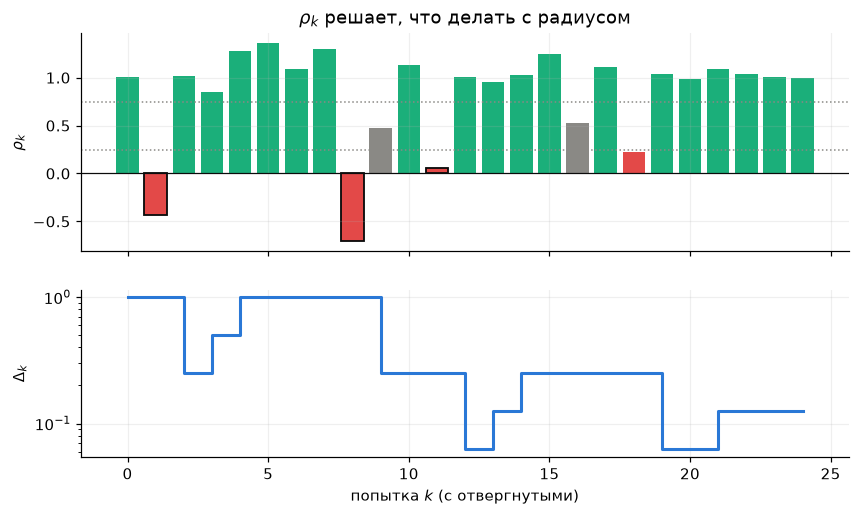

In [6]:
x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step="exact")
print(" k    Δ_k      ρ_k     шаг     |p|")
for i, (xk, p, D, rho, acc) in enumerate(hist[:6]):                                # первые шесть попыток
    print(f"{i:2d}  {D:7.4f}  {rho:7.3f}   {'принят ' if acc else 'ОТВЕРГ.'}  {np.linalg.norm(p):.3f}")

it = np.arange(len(hist))
rho = np.array([h[3] for h in hist]); Dk = np.array([h[2] for h in hist]); acc = np.array([h[4] for h in hist])
col = np.where(rho < 0.25, RED, np.where(rho > 0.75, AQUA, GRAY))                 # Δ/4 / рост, если на границе / без изменений
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
a1.bar(it, rho, color=col, edgecolor=np.where(acc, "none", INK), linewidth=1.2)  # чёрная рамка — шаг отвергнут
for level in (0.25, 0.75):
    a1.axhline(level, color=GRAY, ls=":", lw=1)
a1.axhline(0, color=INK, lw=0.8)
a1.set(ylabel="$\\rho_k$", title="$\\rho_k$ решает, что делать с радиусом")
a2.step(it, Dk, where="post", color=BLUE, lw=2)
a2.set(yscale="log", xlabel="попытка $k$ (с отвергнутыми)", ylabel="$\\Delta_k$")
plt.show()

**Отрицательная кривизна.** Из ловушки $(0.58,2.15)$ доверительная область приходит в минимум $(3,2)$ — за $7$ итераций, без всякого сдвига: в шаре минимум модели есть всегда. Для сравнения на картинке — Ньютон с Армихо из той же точки: он приходит в седло $(0.09,\,2.88)$.

доверительная область: 7 итераций → [3. 2.]; λ_min гессиана в старте = -31.3


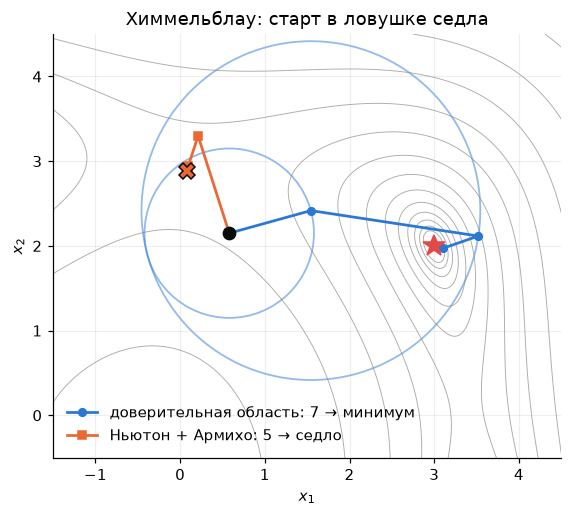

In [7]:
x, k, path, hist = trust_region(him, him_grad, him_hess, (0.58, 2.15), step="exact", tol=1e-10)
print(f"доверительная область: {k} итераций → {x.round(6)}; λ_min гессиана в старте = {np.linalg.eigvalsh(him_hess(np.array([0.58, 2.15])))[0]:.1f}")
x_s, k_s, path_s = newton_ls(him, him_grad, him_hess, (0.58, 2.15))               # Ньютон с Армихо — для сравнения

fig, ax = plt.subplots(figsize=(7, 5))
him_contour(ax, lim=4.5)                                                           # линии уровня Химмельблау
for xk, p, D, rho, acc in hist[:2]:
    ax.add_patch(plt.Circle(xk, D, fill=False, color=BLUE, alpha=0.5, lw=1.2))    # круги доверия первых двух итераций
ax.plot(path[:, 0], path[:, 1], "o-", color=BLUE, ms=5, lw=1.8, label=f"доверительная область: {k} → минимум")
ax.plot(path_s[:, 0], path_s[:, 1], "s-", color=ORANGE, ms=5, lw=1.8, label=f"Ньютон + Армихо: {k_s} → седло")
ax.plot(*x_s, "X", color=ORANGE, mec=INK, ms=11, zorder=8)                         # седло
ax.plot(3, 2, "*", color=RED, ms=15, zorder=8)                                      # минимум
ax.plot(0.58, 2.15, "o", color=INK, ms=8, zorder=9)                                 # старт
ax.set(xlim=(-1.5, 4.5), ylim=(-0.5, 4.5), aspect="equal", xlabel="$x_1$", ylabel="$x_2$", title="Химмельблау: старт в ловушке седла")
ax.legend(loc="lower left")
plt.show()

## 4. Что это даёт численно

- **Какой метод SciPy как глобализован.**

  | `minimize(method=…)` | Направление | Глобализация | Розенброк из $(-1.2,1)$ |
  |---|---|---|---|
  | `"BFGS"` | квази-Ньютон | сильный Вольфе, $c_2=0.9$ | $33$ итерации, $40$ вычислений $f$ |
  | `"L-BFGS-B"` | L-BFGS (память 10) | линейный поиск (Moré–Thuente) | $37$ (с `ftol=0`) |
  | `"trust-exact"` | Ньютон | доверительная область, точный шаг | $25$ |
  | `"dogleg"` | Ньютон | доверительная область, dogleg ($B\succ0$) | $24$ |

  Останов везде — $10^{-6}$, но по-разному: `BFGS` — `gtol` в max-норме градиента, `trust-*` — в евклидовой, `L-BFGS-B` по умолчанию ещё и по относительному уменьшению $f$ (`ftol`) — без `ftol=0` он остановился бы на $36$-й итерации при $\lVert\nabla f\rVert=6\cdot10^{-5}$. Сравнивая солверы, всегда смотрите, *по какому критерию* они остановились.

  Есть гессиан и $n$ до тысяч — `trust-exact`. Гессиана нет — `BFGS`, при больших $n$ — `L-BFGS-B`.
- **PyTorch.** `torch.optim.LBFGS` по умолчанию идёт **без** линейного поиска, с постоянным шагом `lr`; сильный Вольфе включает аргумент `line_search_fn="strong_wolfe"`.
- **IPOPT изнутри** (семинар): `stats()["iterations"]` хранит по итерациям `alpha_pr` — принятую длину шага ($1$ — полный шаг Ньютона, $0.125$ — три деления пополам) и `regularization_size` — сдвиг гессиана, наш $\tau$. На Розенброке IPOPT делает $21$ итерацию, и на второй `alpha_pr` $=0.125$ — как у нашего backtracking. На Химмельблау из $(0.58,2.15)$ сдвиг на первых двух итерациях равен $100$ и $33$ — и метод приходит в минимум $(3,2)$, а не в седло.
- **«Desired error not necessarily achieved due to precision loss»** — линейный поиск больше не различает значения $f$ (часть (e) в `demo06.ipynb`). Перед тем как поднимать `maxiter`, проверьте, не просите ли вы точности ниже $\sqrt{\lambda_{\max}\varepsilon\lvert f\rvert}$.
- **ДЗ 3** (срок 21 октября): ваш Ньютон с Армихо и BFGS — ровно методы раздела 2. Сегодняшняя лекция объясняет, почему они сходятся из любого старта и куда именно.

## 5. Сводка: когда можно пользоваться Ньютоном

**Чистым Ньютоном — только рядом с минимумом,** где гессиан положительно определён и шаг короткий: там он сходится квадратично (арктангенс из $\lvert x_0\rvert<1.39$; цепь — один `solve`). Вдали модель врёт: шаг слишком длинный, $f$ растёт, метод улетает (арктангенс из $2$, Розенброк из $x_1$). Если гессиан индефинитен (собственные числа разных знаков), модель — седло, и шаг ведёт в её седловую точку (Химмельблау: $36\,\%$ стартов не в минимум).

**Поэтому всюду, кроме окрестности решения, — Ньютон с глобализацией:** направление берём из модели, а длину шага проверяет функция (Армихо) или радиус доверия (доверительная область). Теорема §2.3 обещает сходимость к стационарной точке из любого старта, если $B_k\succ0$ — сдвиг $\tau I$ обязателен. Доверительная область обещает то же без сдвига и к тому же уходит от сёдел. У решения оба метода делают чистые ньютоновские шаги — скорость остаётся квадратичной.

| | Когда | Куда приходит | Розенброк из $(-1.2,1)$ |
|---|---|---|---|
| чистый Ньютон | старт близко, $\nabla^2f\succ0$ | куда попадёт: минимум, седло, максимум или $\infty$ | $7$, с выбросом до $f=1412$ |
| Ньютон + Армихо, сдвиг $\tau I$ | из любого старта | стационарная точка, седло возможно | $22$ |
| доверительная область | из любого старта, индефинитный гессиан не страшен | стационарная точка, от сёдел уходит | $25$ |

Если солвер сломался: шаг огромный и $f$ растёт — модель врёт вдали; $\lambda_{\min}(\nabla^2f)<0$ — нужен сдвиг или доверительная область; сошлись в седло — другой старт или доверительная область; «precision loss» — упёрлись в пол точности $\sqrt{\lambda_{\max}\varepsilon\lvert f\rvert}$.

## 6. Итоги лекции

1. **Глобализация** — способ сделать локальный метод сходящимся из любого старта без потери скорости у решения. Сам метод (Ньютон, BFGS, Гаусс–Ньютон) не меняется — меняется то, *насколько далеко мы верим его модели* (введение, раздел 1).
2. **Линейный поиск:**
   - Армихо требует уменьшения, соразмерного обещанию: доля $c_1$ от $\alpha\,g^\top p$;
   - backtracking даёт шаг не длиннее и не короче нужного;
   - Вольфе запрещает слишком короткие шаги и гарантирует $s^\top y>0$ для BFGS.

   Арктангенс из введения: чистый Ньютон из $x_0=2$ за пять шагов — в $-2.3\cdot10^{10}$, с Армихо за пять итераций — в минимум; разница — одно деление шага пополам. На цепи BFGS спасает не Вольфе, а масштабирование $H_0$: $27$ итераций (часть (e) в `demo06.ipynb`).
3. **Теорема о глобальной сходимости:** при $B_k$ с собственными числами в $[m_B,M_B]$ и backtracking по Армихо $\nabla f(x_k)\to0$ из любого старта. Это сходимость к *стационарной* точке: на Химмельблау из $(0.58,2.15)$ Ньютон с Армихо приходит в седло, доверительная область из той же точки — в минимум $(3,2)$ (раздел 2.3, упражнение 6.2, семинар).
4. **Доверительная область:** сначала радиус $\Delta$, потом шаг. $\rho$ — отношение фактического уменьшения к обещанному — сам двигает $\Delta$. Решение подзадачи — $(B+\lambda I)p=-g$: Левенберг–Марквардт и сдвиг $\tau I$ — частные случаи. Точка Коши гарантирует сходимость ($14\,110$ итераций на Розенброке), dogleg и точный шаг — скорость ($24$ и $25$) (раздел 3).
5. **Когда Ньютон можно:** близко к минимуму с $\nabla^2f\succ0$ — чистым; иначе — с Армихо и сдвигом $\tau I$ или в доверительной области; обе гарантии — к стационарной точке, минимум надёжнее даёт доверительная область (раздел 5).

## 7. Что дальше

**Лекция 7** (21.10) — производные: конечные разности и их U-кривая ошибки, алгоритмическое дифференцирование вперёд и назад, CasADi всерьёз. **Лекция 8** — ограничения-равенства: множители Лагранжа возвращаются уже как алгоритм. Слияние линейного поиска с ограничениями — merit-функции и фильтры — в лекции 13 (SQP).

**Сопряжённые градиенты** — Ньютон без матрицы для задач с тысячами переменных — из этой лекции убраны и будут рассказаны отдельно.

**ДЗ 3** — срок 21 октября: спуск, Ньютон, BFGS и Гаусс–Ньютон своими руками ([карточка](../../homeworks/hw03.md)).

**Литература к лекции.**
- Diehl, *Lecture Notes on Numerical Optimization*, глава *Globalization Strategies*: Armijo backtracking, Wolfe, global convergence, trust region, Cauchy point.
- Nocedal & Wright:
  - гл. 3 — §3.1 условия Вольфе, §3.2 теорема Зойтендейка, §3.5 алгоритмы линейного поиска;
  - гл. 4 — доверительная область: §4.1 точка Коши и dogleg, §4.3 точное решение.
- Boyd & Vandenberghe, §9.2 — backtracking.
- Поляк, «Введение в оптимизацию», гл. 1 — выбор шага.

## 8. Семинар: глобализация в CasADi и IPOPT

Весь семинар — за ноутбуком [`seminar06.ipynb`](seminar06.ipynb) (~30 минут). Нужен пакет CasADi: `uv sync --group casadi`; в Colab первая ячейка ставит его сама. Основы CasADi — семинар лекции 4 (Л4, §11.1).

| Мин | Часть |
|-----|------|
| 8 | **Часть 1 — производные из CasADi и наш метод доверительной области.** $f$, $\nabla f$, $\nabla^2f$ Розенброка и Химмельблау одной строкой; `trust_region` на этих производных — $25$ итераций на Розенброке; ловушка седла $(0.58,2.15)$: Ньютон с Армихо — в седло, доверительная область — в минимум $(3,2)$ |
| 12 | **Часть 2 — что делает IPOPT.** Из той же ловушки IPOPT приходит в $(3,2)$: `regularization_size` $=100$ и $33$ — сдвиг гессиана всякий раз, когда он не положительно определён; на Розенброке `alpha_pr` $=0.125$ на второй итерации — три деления пополам, как у нашего backtracking |
| 10 | **Часть 3 — соревнование.** Химмельблау из $(0,0)$, откуда чистый Ньютон идёт в максимум: кто придёт в минимум за меньшее число вычислений $f$ — свой метод, SciPy или IPOPT |

Дома: упражнения 6.0–6.5 (разбор — [`exercises06.ipynb`](exercises06.ipynb)), затем демонстрации (a)–(e) в `demo06.ipynb` и интерактивная страница.

## 9. Упражнения

Все задачи — домашние; у каждой курсивом — её суть одной фразой. Разбор с проверкой кодом — ноутбук [`exercises06.ipynb`](exercises06.ipynb), краткие ответы — [`exercises06.md`](exercises06.md).

**6.0. Разминка — счёт руками.** Три пункта по минуте. *Суть: Армихо, $\rho$ и точка Коши — на бумаге.*

- (а) $f(x)=x^2$, $x=1$, $p=-2$, $c_1=\tfrac12$. При каких $\alpha$ выполнено правило Армихо? Какой шаг даст backtracking от $\alpha=1$?
- (б) Модель обещала уменьшение $4$, фактически $f$ выросла на $1$. Чему равно $\rho$? Что происходит с шагом и с $\Delta$?
- (в) $g=(1,0)$, $B=\operatorname{diag}(1,10)$, $\Delta=0.5$. Найдите точку Коши (формула — упражнение 6.3). Изменится ли ответ при $\Delta=2$?

**6.1. Теорема о глобальной сходимости** (для желающих). *Суть: каждый шаг съедает кусок $\lVert g\rVert^2$, а съесть можно лишь конечное.*

- (а) Докажите теорему §2.3 по плану из четырёх строк: выведите лемму о спуске из липшицевости, оценку $\alpha_k\ge\min(1,\bar\alpha_k/2)$ и постоянную $C$ через $c_1$, $L$, $m_B$, $M_B$.
- (б) Что теорема говорит о спуске ($B=I$) на Розенброке — и чего не говорит?

**6.2. Сломайте Ньютона: сходимость в седло** (с кодом). *Суть: глобальная сходимость — к стационарной точке, а не к минимуму.*

- (а) Запустите `newton_ls` из `l6helpers.py` (Ньютон с Армихо, сдвиг $\tau I$ только когда шаг не спуск) на Химмельблау из $(0.58,2.15)$. Куда пришёл метод? Посчитайте собственные числа гессиана в этой точке.
- (б) Замените правило сдвига на «всегда, когда $\lambda_{\min}\le10^{-3}$» (`shift="always"`). Куда теперь приходит метод? Почему седло перестало притягивать?

**6.3. Точка Коши — спуск в маскировке** (с кодом). *Суть: точка Коши даёт сходимость, но скорость спуска.*

- (а) Выведите формулу точки Коши: минимизируйте $m(-t\,g)$ по $t\ge0$ при $t\lVert g\rVert\le\Delta$. Ответ: $p_C=-\tau\,\frac{\Delta}{\lVert g\rVert}\,g$, где $\tau=\min\big(\lVert g\rVert^3/(\Delta\,g^\top Bg),\,1\big)$ при $g^\top Bg>0$ и $\tau=1$ иначе.
- (б) Запустите `trust_region(..., step="cauchy")` на Розенброке. Сравните число итераций ($14\,110$) с dogleg ($24$) и спуском с backtracking ($13\,756$, Л4). Почему числа точки Коши и спуска так близки?

**6.4. Dogleg руками.** *Суть: ломаная Пауэлла — компромисс между точкой Коши и точкой Ньютона.*

$g=(4,2)$, $B=\operatorname{diag}(2,1)$. Найдите минимум модели вдоль $-g$, точку Ньютона и шаг dogleg при $\Delta=1,\ 2.6,\ 3$. При каком $\Delta$ шаг совпадает с точкой Ньютона?

**6.5. Левенберг–Марквардт = доверительная область.** *Суть: $\lambda$ и $\Delta$ — две ручки одного механизма.*

Для $J^\top J=\operatorname{diag}(1,100)$, $J^\top r=(1,1)$ найдите шаг Левенберга–Марквардта при $\lambda=0,\ 1,\ 10,\ 100$ и его длину. Какому $\Delta$ соответствует каждый $\lambda$? Почему «уменьшить $\Delta$» и «увеличить $\lambda$» — одно и то же?

## Вопросы для самопроверки

1. Что такое глобализация и чем «глобальная сходимость» отличается от «сходимости к глобальному минимуму»? Приведите пример с числами.
2. Запишите правило Армихо через $\varphi(\alpha)$. Что оно означает, почему $c_1$ берут маленьким и почему backtracking не даёт слишком коротких шагов?
3. Сформулируйте теорему о глобальной сходимости линейного поиска. Какое условие на $B_k$ в ней главное и как его обеспечить для Ньютона?
4. Как устроен шаг доверительной области: подзадача, $\rho$, правила для $\Delta$? Что делает метод при $\rho<0$?
5. Как связаны $\lambda$ Левенберга–Марквардта, сдвиг $\tau I$ и радиус $\Delta$? Сформулируйте условия Moré–Sorensen.
6. Что такое точка Коши и dogleg? Почему метод только с точкой Коши сходится, но медленно?